<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 1. Aspectos generales

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Aplica segmentacion de clientes con **Bisecting K-Means** sobre las variables RFM
(Recency, Frequency, Monetary) calculadas a partir del merge en capa **silver**.

Bisecting K-Means es una variante jerarquica divisiva de K-Means: parte de un unico cluster
y lo divide recursivamente usando K-Means binario, lo que generalmente requiere menos
iteraciones y memoria que el K-Means clasico.

Flujo: `silver/merge_pyspark` ---> limpieza ---> calculo RFM ---> Bisecting K-Means ---> `gold/hym_bisecting_kmeans`

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, avg, count, sum as spark_sum, datediff, max as spark_max
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import BisectingKMeans
from pyspark.ml import Pipeline
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches

In [2]:
spark = SparkSession.builder \
    .appName("HYM_BisectingKMeans") \
    .config("spark.sql.adaptive.enabled", "true") \
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true") \
    .config("spark.driver.memory", "4g") \
    .config("spark.executor.memory", "4g") \
    .config("spark.sql.shuffle.partitions", "50") \
    .config("spark.memory.fraction", "0.8") \
    .getOrCreate()

spark.sparkContext.setCheckpointDir("/tmp/spark_checkpoint")
spark

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 2. Rutas de capas

In [3]:
SILVER = "./silver"
GOLD   = "./gold"

import os
os.makedirs(GOLD, exist_ok=True)

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 3. Carga desde capa silver

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Lee el DataFrame unificado desde `silver/merge_pyspark` y filtra registros con `price` nulo
o `age` nulo, que corresponden a transacciones o clientes sin informacion valida.

In [4]:
%%time
df_raw = spark.read.parquet(f"{SILVER}/merge_pyspark")

df_clean = (
    df_raw
    .select("customer_id", "Fecha", "price", "age")
    .filter(col("price").isNotNull())
    .filter(col("age").isNotNull() & (col("age") > 0))
)

df_clean.createOrReplaceTempView("clean_transactions")
print(f"Registros tras limpieza: {df_clean.count():,}")

Registros tras limpieza: 31,648,066
CPU times: user 6 ms, sys: 0 ns, total: 6 ms
Wall time: 5.39 s


<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 4. Calculo de variables RFM

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Calcula las tres metricas RFM en una sola pasada SQL para minimizar shuffles:

- **Recency**: dias entre la ultima y penultima compra (ventana `LAG` por cliente).
- **Frequency**: numero total de transacciones del cliente.
- **Monetary**: suma del precio pagado por el cliente.

In [5]:
%%time
df_rfm = spark.sql("""
WITH ranked AS (
    SELECT
        customer_id,
        price,
        Fecha,
        LAG(Fecha) OVER (PARTITION BY customer_id ORDER BY Fecha) AS prev_fecha,
        ROW_NUMBER() OVER (PARTITION BY customer_id ORDER BY Fecha DESC) AS rnum
    FROM clean_transactions
),
lastbuy AS (
    SELECT customer_id, DATEDIFF(Fecha, prev_fecha) AS Recency
    FROM ranked
    WHERE rnum = 1 AND prev_fecha IS NOT NULL
),
freq_amount AS (
    SELECT
        customer_id,
        COUNT(1)   AS Frequency,
        SUM(price) AS Monetary
    FROM clean_transactions
    GROUP BY customer_id
)
SELECT
    f.customer_id,
    CAST(f.Frequency AS INT)   AS Frequency,
    CAST(f.Monetary      AS FLOAT) AS Monetary,
    CAST(l.Recency      AS INT)   AS Recency
FROM freq_amount f
INNER JOIN lastbuy l ON f.customer_id = l.customer_id
""")

df_rfm = df_rfm.checkpoint()
print(f"Clientes con RFM completo: {df_rfm.count():,}")
df_rfm.describe().show()

Clientes con RFM completo: 907,262
+-------+--------------------+-----------------+------------------+------------------+
|summary|         customer_id|        Frequency|          Monetary|           Recency|
+-------+--------------------+-----------------+------------------+------------------+
|  count|              907262|           907262|            907262|            907262|
|   mean|                null|33.20348146400929|0.9252677800357777| 95.09396954793654|
| stddev|                null|44.83247195210684|1.3844537868924416|118.65969244183664|
|    min|00000dbacae5abe5e...|                2|      0.0033559322|                 1|
|    max|ffffd7744cebcf3ac...|             1895|         57.676407|               731|
+-------+--------------------+-----------------+------------------+------------------+

CPU times: user 6.33 ms, sys: 2.18 ms, total: 8.51 ms
Wall time: 28.1 s


<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 5. Exploracion de variables RFM

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Boxplot con muestra del 5 % para no saturar el driver.
Se usa escala logaritmica dado el rango amplio de las tres variables.

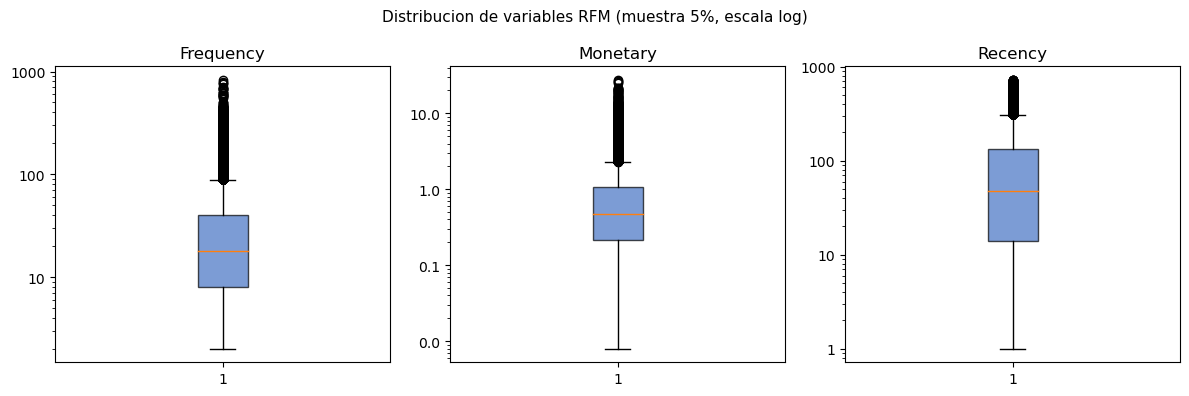

In [6]:
sample_pd = df_rfm.select("Frequency", "Monetary", "Recency").sample(fraction=0.05, seed=42).toPandas()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col_name in zip(axes, ["Frequency", "Monetary", "Recency"]):
    ax.boxplot(sample_pd[col_name].dropna(), vert=True, patch_artist=True,
               boxprops=dict(facecolor="#4472C4", alpha=0.7))
    ax.set_title(col_name)
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
fig.suptitle("Distribucion de variables RFM (muestra 5%, escala log)", fontsize=11)
plt.tight_layout()
plt.show()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 6. Preparacion de features

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Ensambla las tres variables en un vector y las escala con `StandardScaler`.
El escalado es necesario porque Bisecting K-Means usa distancia euclidiana y las magnitudes
de `Monetary` (miles) y `Recency` (decenas) son muy distintas.

In [7]:
assembler = VectorAssembler(
    inputCols=["Frequency", "Monetary", "Recency"],
    outputCol="features_raw",
    handleInvalid="skip"
)

scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withStd=True,
    withMean=False
)

pipeline_prep = Pipeline(stages=[assembler, scaler])
prep_model    = pipeline_prep.fit(df_rfm)
df_features   = prep_model.transform(df_rfm).select("customer_id", "Frequency", "Monetary", "Recency", "features")
df_features   = df_features.checkpoint()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 7. Seleccion del numero optimo de clusters

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Recorre un rango de valores de `k` y registra el `trainingCost` (suma de distancias
al cuadrado dentro de cada cluster, WSSSE) para cada uno.

Bisecting K-Means construye el arbol de divisiones internamente, por lo que
cada iteracion del bucle es significativamente mas rapida que en K-Means clasico.

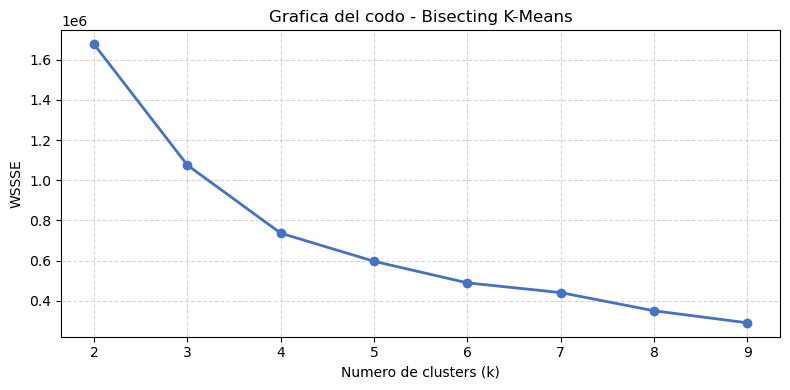

CPU times: user 393 ms, sys: 180 ms, total: 573 ms
Wall time: 1min 5s


In [8]:
%%time
costs   = []
K_range = range(2, 10)

for k in K_range:
    bkm  = BisectingKMeans(featuresCol="features", k=k, seed=42, maxIter=6)
    m    = bkm.fit(df_features)
    costs.append(m.summary.trainingCost)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(K_range), costs, marker="o", color="#4472C4", linewidth=2)
ax.set_xlabel("Numero de clusters (k)")
ax.set_ylabel("WSSSE")
ax.set_title("Grafica del codo - Bisecting K-Means")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 8. Entrenamiento del modelo final

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Entrena el modelo definitivo con el `k` identificado en la grafica del codo.
Se incrementa `maxIter` a 30 para asegurar convergencia.

In [9]:
%%time
BEST_K = 6

bkm_final    = BisectingKMeans(featuresCol="features", k=BEST_K, seed=42, maxIter=30)
bkm_model    = bkm_final.fit(df_features)
df_clustered = bkm_model.transform(df_features)

consolidado = (
    df_clustered
    .select("customer_id", "Frequency", "Monetary", "Recency", "prediction")
    .withColumnRenamed("prediction", "cluster")
)
consolidado.show(5)

+--------------------+---------+-----------+-------+-------+
|         customer_id|Frequency|   Monetary|Recency|cluster|
+--------------------+---------+-----------+-------+-------+
|0000d6c053fc8f938...|        7| 0.14057627|      3|      0|
|000114c6996ef5703...|       18| 0.33698305|    486|      3|
|0002d2ef78ec29c03...|       43|  1.3823221|     45|      1|
|000346516dd355b40...|       20| 0.45686442|     39|      0|
|00078b3110954a85c...|        2|0.042338982|      9|      0|
+--------------------+---------+-----------+-------+-------+
only showing top 5 rows

CPU times: user 34.7 ms, sys: 8.87 ms, total: 43.6 ms
Wall time: 1min 6s


<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 9. Perfil de clusters

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Agrega las metricas medias por cluster para caracterizar cada segmento:
numero de clientes, frecuencia media, gasto medio y recencia media.

In [10]:
perfil = (
    consolidado.groupBy("cluster")
    .agg(
        count("customer_id").alias("n_clientes"),
        avg("Frequency").alias("freq_media"),
        avg("Monetary").alias("Monetary_media"),
        avg("Recency").alias("Recency_media")
    )
    .orderBy("cluster")
)
perfil.show()

+-------+----------+------------------+-------------------+------------------+
|cluster|n_clientes|        freq_media|     Monetary_media|     Recency_media|
+-------+----------+------------------+-------------------+------------------+
|      0|    492088|14.570381720342702| 0.3786017933710635|54.544557071092974|
|      1|    182127| 53.31016817934738| 1.4391551958008655| 43.47588770473351|
|      2|    110392|15.127119718820204|0.41219045390910236|251.93650808029568|
|      3|     46234|10.497512653025911|0.28664237009790045|460.04944413202406|
|      4|     66948|123.38981000179244|  3.616347949187331| 33.47668339606859|
|      5|      9473| 298.6561807241634|  9.520053265025041| 20.41507442204159|
+-------+----------+------------------+-------------------+------------------+



<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 10. Visualizacion de resultados

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Graficos de distribucion de clientes y gasto medio por cluster.

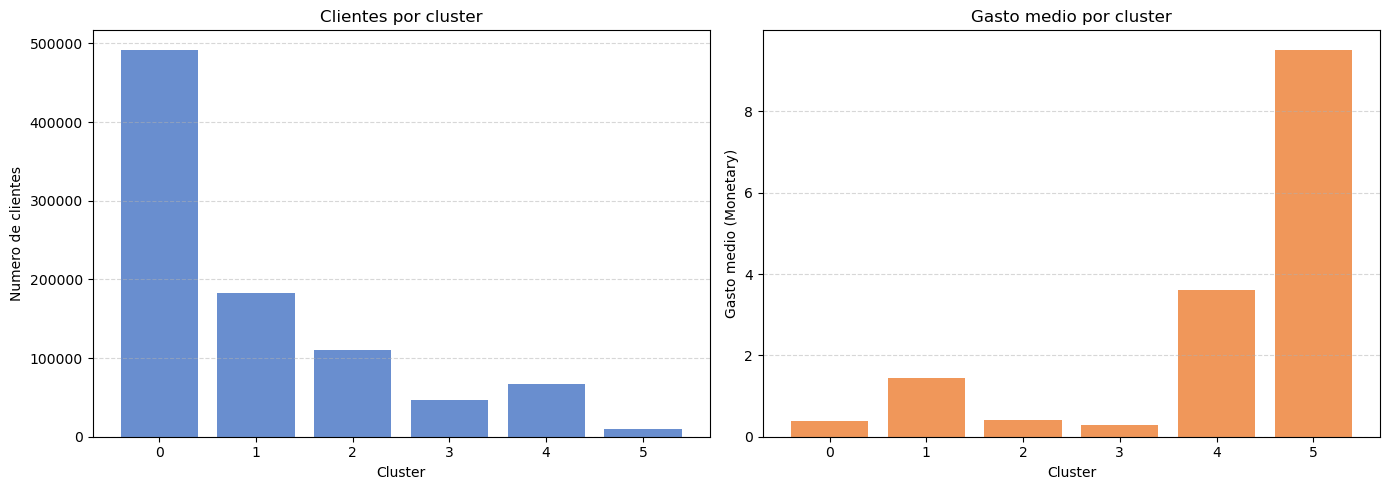

In [11]:
perfil_pd = perfil.toPandas()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(perfil_pd["cluster"].astype(str), perfil_pd["n_clientes"], color="#4472C4", alpha=0.8)
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Numero de clientes")
axes[0].set_title("Clientes por cluster")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

axes[1].bar(perfil_pd["cluster"].astype(str), perfil_pd["Monetary_media"], color="#ED7D31", alpha=0.8)
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Gasto medio (Monetary)")
axes[1].set_title("Gasto medio por cluster")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Scatter plot Frequency vs Recency coloreado por cluster para visualizar la separacion espacial
de los segmentos sobre una muestra del 5 %.

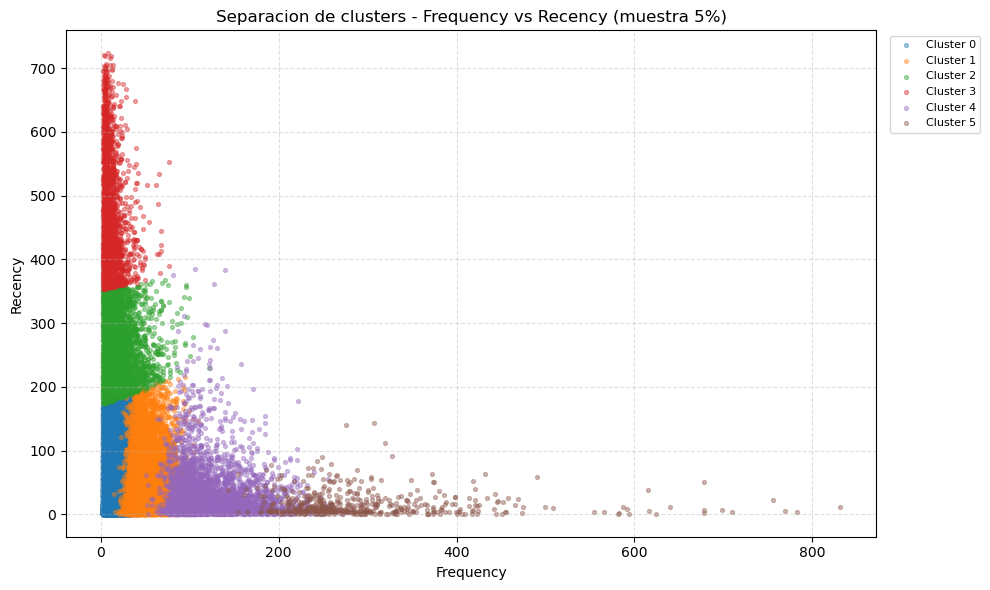

In [12]:
scatter_pd = consolidado.select("Frequency", "Recency", "cluster").sample(fraction=0.05, seed=42).toPandas()

colors = plt.cm.tab10.colors
fig, ax = plt.subplots(figsize=(10, 6))
for cl in sorted(scatter_pd["cluster"].unique()):
    sub = scatter_pd[scatter_pd["cluster"] == cl]
    ax.scatter(sub["Frequency"], sub["Recency"], s=8, alpha=0.4,
               color=colors[cl % len(colors)], label=f"Cluster {cl}")
ax.set_xlabel("Frequency")
ax.set_ylabel("Recency")
ax.set_title("Separacion de clusters - Frequency vs Recency (muestra 5%)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Heatmap de metricas medias normalizadas por cluster para comparar el perfil
de cada segmento de forma compacta.

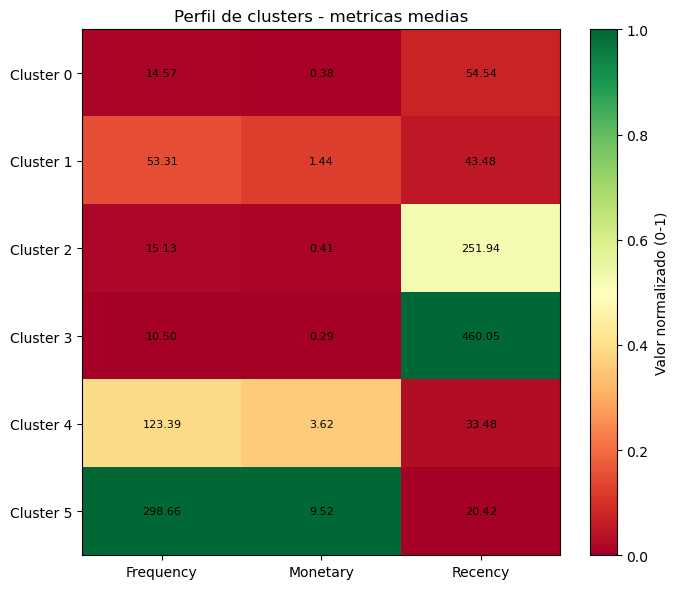

In [13]:
import numpy as np

heat_pd = perfil_pd.set_index("cluster")[["freq_media", "Monetary_media", "Recency_media"]]
heat_norm = (heat_pd - heat_pd.min()) / (heat_pd.max() - heat_pd.min())

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(heat_norm.values, cmap="RdYlGn", aspect="auto", vmin=0, vmax=1)
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["Frequency", "Monetary", "Recency"])
ax.set_yticks(range(len(heat_norm)))
ax.set_yticklabels([f"Cluster {i}" for i in heat_norm.index])
for i in range(len(heat_norm)):
    for j in range(3):
        ax.text(j, i, f"{heat_pd.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="Valor normalizado (0-1)")
ax.set_title("Perfil de clusters - metricas medias")
plt.tight_layout()
plt.show()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 11. Escritura en capa gold

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Guarda el DataFrame con la asignacion de clusters en `gold/hym_bisecting_kmeans`.

In [14]:
consolidado.write.mode("overwrite").parquet(f"{GOLD}/hym_bisecting_kmeans")
print("Escritura en gold/hym_bisecting_kmeans completada")

spark.read.parquet(f"{GOLD}/hym_bisecting_kmeans").select("cluster").groupBy("cluster").count().orderBy("cluster").show()

Escritura en gold/hym_bisecting_kmeans completada
+-------+------+
|cluster| count|
+-------+------+
|      0|492088|
|      1|182127|
|      2|110392|
|      3| 46234|
|      4| 66948|
|      5|  9473|
+-------+------+



In [15]:
spark.stop()